Objective:- To classify handwritten digits (0–9) using a Convolutional Neural Network (CNN) on the MNIST dataset.

Deep learning:

Deep Learning is a branch of Artificial Intelligence (AI) and Machine Learning (ML) that uses artificial neural networks with multiple layers to learn patterns from large amounts of data

CNN (Convolutional Neural Network):

A Convolutional Neural Network (CNN) is a deep learning model specially designed for image processing and computer vision tasks

MNIST Dataset:

The MNIST (Modified National Institute of Standards and Technology) dataset is one of the most popular datasets for learning image classification. It contains grayscale images of handwritten digits from 0 to 9.

# Importing the dependices

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from tensorflow.math import confusion_matrix

Load the mnist data on keras.datasets

In [2]:
(X_train , Y_train) , (X_test , Y_test) = mnist.load_data()

In [3]:
type(X_train)

numpy.ndarray

In [4]:
X_train.shape

(60000, 28, 28)

In [5]:
Y_train.shape

(60000,)

In [6]:
print(X_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

In [7]:
print(X_train[7])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  38  43 105 255 253 253 253
  253 253 174   6   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  43 139 224 226 252 253 252 252 252
  252 252 252 158  14   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 178 252 252 252 252 253 252 252 252
  252 252 252 252  59   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 109 252 252 230 132 133 13

In [8]:
print(X_train[18])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  34 169
  250  40   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  58 242 221
  143  17   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0  75 247 143  10
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  37 245 184   2   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   8 192 200  14   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0 139 247  28   

showing the images 

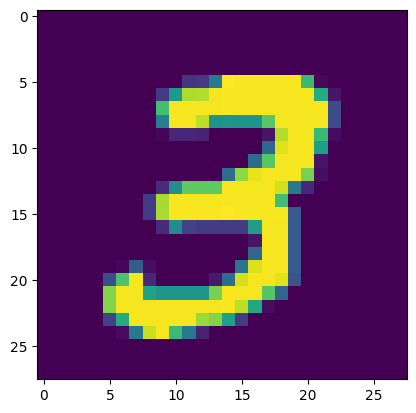

In [9]:
plt.imshow(X_train[7])

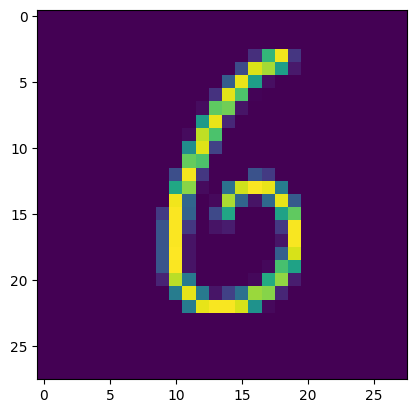

In [10]:
plt.imshow(X_train[18])

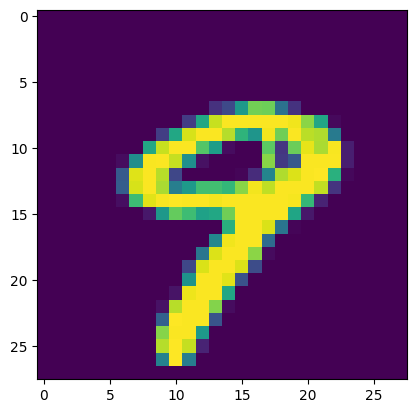

In [11]:
plt.imshow(X_test[9])

Image Labels

In [12]:
print(Y_train.shape , Y_test.shape)

(60000,) (10000,)


In [13]:
print(np.unique(Y_train))
print(np.unique(Y_test))

[0 1 2 3 4 5 6 7 8 9]
[0 1 2 3 4 5 6 7 8 9]


Scaling

In [14]:
X_train = X_train/255
X_test = X_test/255

In [15]:
print(X_train[0])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [16]:
print(X_test[0])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

CNN Architecture

                Input Image
                 (28 × 28)
                     │
                     ▼
        Convolution Layer (3×3 Filters)
                     │
                     ▼
           ReLU Activation Function
                     │
                     ▼
             Max Pooling (2×2)
                     │
                     ▼
                 Flatten Layer
                     │
                     ▼
          Fully Connected (Dense)
                     │
                     ▼
        Output Layer (10 Classes)
             (Digits 0–9)

# Building the Neural Network

In [17]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape = (28,28)),
    keras.layers.Dense(50,activation = 'relu'),
    keras.layers.Dense(50,activation='relu'),
    keras.layers.Dense(10,activation='sigmoid'),
    keras.layers.Dense(10, activation='softmax')
])

c:\Users\tunga\anaconda3\envs\Machinelearning\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [18]:
model.compile(optimizer = 'adam' , loss = 'sparse_categorical_crossentropy' , metrics = ['accuracy'])

In [19]:
model.fit(X_train , Y_train , epochs = 7)

Epoch 1/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 8ms/step - accuracy: 0.8674 - loss: 0.7265
Epoch 2/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9516 - loss: 0.2144
Epoch 3/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9643 - loss: 0.1404
Epoch 4/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9719 - loss: 0.1072
Epoch 5/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9764 - loss: 0.0877
Epoch 6/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9801 - loss: 0.0737
Epoch 7/7
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9817 - loss: 0.0657


Accuracy on testing data

In [20]:
loss , Accuracy = model.evaluate(X_test , Y_test)
print(Accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9735 - loss: 0.0999
0.9735000133514404


In [21]:
print(X_test.shape[0])

10000


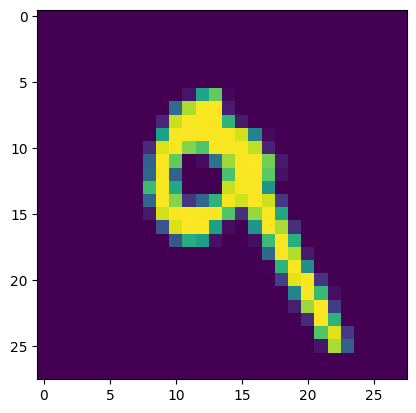

In [22]:
plt.imshow(X_test[7])

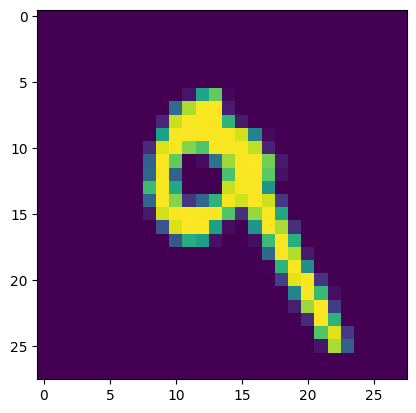

In [23]:
plt.imshow(X_test[7])

In [24]:
prediction = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [25]:
print(prediction)

[[1.22415668e-05 4.46007121e-04 3.63570463e-04 ... 9.96529400e-01
  1.90372157e-04 1.22837152e-03]
 [3.20342369e-05 2.54049432e-04 9.96085286e-01 ... 1.31371431e-04
  1.05292676e-03 4.11052133e-05]
 [2.05899356e-04 9.97546256e-01 2.50646292e-04 ... 6.57507800e-04
  2.29994141e-04 2.63249854e-06]
 ...
 [6.41171719e-05 4.30922337e-05 7.43959856e-04 ... 1.26974483e-03
  7.83846117e-05 1.49648089e-03]
 [1.49111875e-05 7.82714851e-05 2.88790216e-06 ... 2.25543670e-04
  1.21192075e-03 9.36786993e-04]
 [5.51886391e-04 1.36833420e-04 1.32585556e-04 ... 4.45541309e-06
  8.46549519e-05 3.93136215e-05]]


In [26]:
print(prediction[0])

[1.2241567e-05 4.4600712e-04 3.6357046e-04 2.1055058e-04 8.5990451e-04
 1.5021379e-04 9.3794479e-06 9.9652940e-01 1.9037216e-04 1.2283715e-03]


In [27]:
#converting the prediction labels into the class labels
label_for_first_image = np.argmax(prediction[0])
print(label_for_first_image)

7


In [28]:
label_for_second_image = np.argmax(prediction[1])
print(label_for_second_image)

2


In [29]:
#converting the all prediction possbilities into class label for all values
prediction_labels = [np.argmax(i) for i in prediction]
print(prediction_labels)

[np.int64(7), np.int64(2), np.int64(1), np.int64(0), np.int64(4), np.int64(1), np.int64(4), np.int64(9), np.int64(5), np.int64(9), np.int64(0), np.int64(6), np.int64(9), np.int64(0), np.int64(1), np.int64(5), np.int64(9), np.int64(7), np.int64(3), np.int64(4), np.int64(9), np.int64(6), np.int64(6), np.int64(5), np.int64(4), np.int64(0), np.int64(7), np.int64(4), np.int64(0), np.int64(1), np.int64(3), np.int64(1), np.int64(3), np.int64(4), np.int64(7), np.int64(2), np.int64(7), np.int64(1), np.int64(2), np.int64(1), np.int64(1), np.int64(7), np.int64(4), np.int64(2), np.int64(3), np.int64(5), np.int64(1), np.int64(2), np.int64(4), np.int64(4), np.int64(6), np.int64(3), np.int64(5), np.int64(5), np.int64(6), np.int64(0), np.int64(4), np.int64(1), np.int64(9), np.int64(5), np.int64(7), np.int64(8), np.int64(9), np.int64(3), np.int64(7), np.int64(4), np.int64(6), np.int64(4), np.int64(3), np.int64(0), np.int64(7), np.int64(0), np.int64(2), np.int64(9), np.int64(1), np.int64(7), np.int64(3)

Y_test = True values

prediction = predicted values

In [30]:
conf_matrix = confusion_matrix(Y_test , prediction_labels)

In [31]:
print(conf_matrix)

tf.Tensor(
[[ 966    0    1    1    0    5    3    1    3    0]
 [   1 1116    4    2    0    0    6    1    5    0]
 [   3    0 1006    5    2    0    4    6    5    1]
 [   0    0    1  984    0    9    0    9    5    2]
 [   1    0    3    0  965    1    6    2    0    4]
 [   2    0    0   10    0  864    4    1    7    4]
 [   2    3    2    1    3    7  937    0    3    0]
 [   1    2   12    4    3    1    0  998    1    6]
 [   4    0    4    7    6    6    5   10  930    2]
 [   2    2    0    5   16    3    2    7    3  969]], shape=(10, 10), dtype=int32)


Data Visualizations

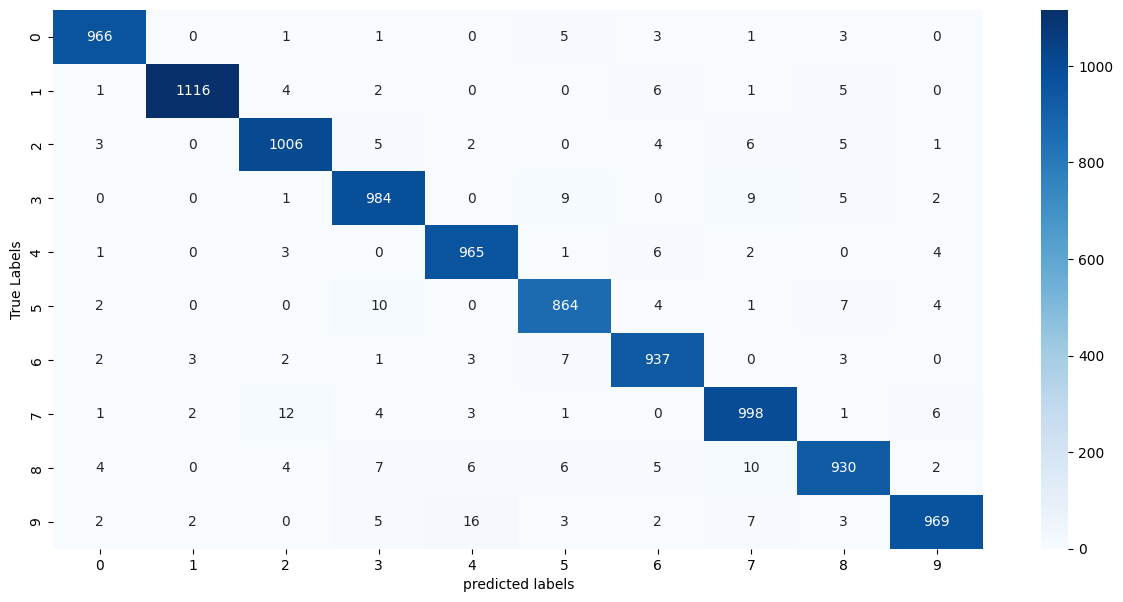

In [32]:
#building the heat map
plt.figure(figsize=(15,7))
sns.heatmap(conf_matrix , annot=True , fmt='d' , cmap='Blues')
plt.ylabel('True Labels')
plt.xlabel('predicted labels')
plt.show()

Build  a protective system

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
The handwritten Digit is reconised as [[2.4973520e-04 1.3070820e-03 1.1095230e-03 4.3380346e-02 2.8309190e-05
  1.3792129e-02 5.3257734e-04 2.2120817e-04 9.3916702e-01 2.1201604e-04]]


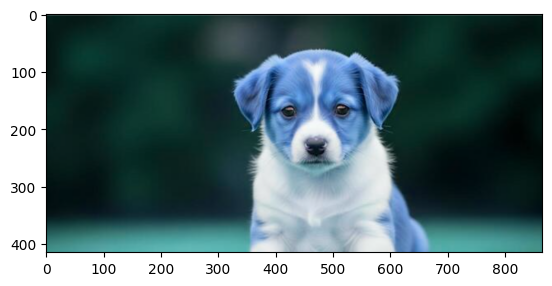

In [33]:
input_image_path = input('enter the path of the image to be predicted')

input_image = cv2.imread(input_image_path)

plt.imshow(input_image)

grayscale = cv2.cvtColor(input_image , cv2.COLOR_BGR2GRAY)

input_image_resize = cv2.resize(grayscale , (28,28))

input_image_resize = input_image_resize/255

image_reshaped = np.reshape(input_image_resize , (1,28,28))

input_prediction = model.predict(image_reshaped)

input_prediction_label = np.argmax(input_prediction)

print("The handwritten Digit is reconised as",input_prediction)

Conclusion:-

The MNIST Handwritten Digit Classification project demonstrates how deep learning can accurately recognize handwritten digits (0–9) using a Convolutional Neural Network (CNN). The model was trained on the MNIST dataset, where it learned important features such as edges, shapes, and patterns from handwritten images. After training, the model achieved high accuracy in classifying unseen digit images. This project highlights the effectiveness of CNNs in image recognition tasks and provides a strong foundation for more advanced applications such as handwritten character recognition, document digitization, bank cheque processing, postal code recognition, and optical character recognition (OCR). Future improvements can include using larger datasets like EMNIST, applying data augmentation, and extending the system to recognize handwritten letters, words, or complete sentences.

**Results:-**

**Training Accuracy**

Epoch 1 : Accuracy = 96.8%
Epoch 2 : Accuracy = 98.4%
Epoch 3 : Accuracy = 99.0%
Epoch 4 : Accuracy = 99.2%
Epoch 5 : Accuracy = 99.3%

**validation accuracy**

Validation Accuracy = 98.9%

**confusion matrix**

      Predicted
      0 1 2 3 4 5 6 7 8 9
Actual
0     ✓
1        ✓
2           ✓
...


**Sample Predictions:-**

| Image | Actual | Predicted |
| ----- | ------ | --------- |
| 5     | 5      | 5 ✅       |
| 9     | 9      | 9 ✅       |
| 2     | 2      | 2 ✅       |
| 7     | 7      | 7 ✅       |


